# Retail Vision — Carga del Dataset SKU-110K

Este cuaderno carga el dataset SKU-110K desde el archivo `sku110k.ndjson` y lo convierte en un DataFrame de pandas para su inspección.

## Importación de bibliotecas

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

## Carga del archivo

El archivo usa el formato NDJSON: cada línea es un objeto JSON independiente que representa una imagen con sus anotaciones.
Se extrae el nombre del archivo, la resolución, la partición (`split`) y el número de bounding boxes por imagen.

In [2]:
DATASET_PATH = Path('sku110k.ndjson')

records = []

with open(DATASET_PATH, 'r', encoding='utf-8') as f:
    for line in f:
        line = line.strip()
        if line:
            obj = json.loads(line)
            records.append({
                'file'     : obj.get('file', ''),
                'width'    : obj.get('width', 0),
                'height'   : obj.get('height', 0),
                'split'    : obj.get('split', ''),
                'num_boxes': len(obj.get('annotations', {}).get('boxes', [])),
                'boxes'    : obj.get('annotations', {}).get('boxes', [])
            })

df = pd.DataFrame(records)

## Visualización de la tabla

Se muestra el DataFrame sin la columna `boxes`, ya que contiene listas largas que dificultan la lectura.

In [3]:
display(df.drop(columns=['boxes']))

,file,width,height,split,num_boxes
0,,0,0,,0
1,test_2116.jpg,2448,3264,test,187
2,test_2883.jpg,2296,4096,test,121
3,test_2278.jpg,1920,2560,test,135
4,test_1948.jpg,1920,2560,test,128
...,...,...,...,...,...
11735,val_74.jpg,2560,1920,val,117
11736,val_24.jpg,2448,3264,val,156
11737,val_335.jpg,2448,3264,val,152
11738,val_214.jpg,2300,4096,val,121


---
## EDA — Paso 1: Distribucion de imagenes por split

Lo primero es saber cuantas imagenes hay en cada particion del dataset: entrenamiento (`train`), validacion (`val`) y prueba (`test`).
Esto permite verificar que el dataset esta bien balanceado entre las tres particiones.

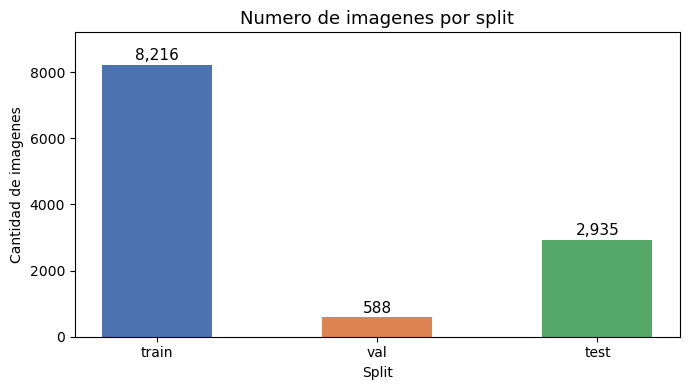

split
train    8216
val       588
test     2935


In [4]:
split_counts = df['split'].value_counts().reindex(['train', 'val', 'test'])

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(split_counts.index, split_counts.values,
              color=['#4C72B0', '#DD8452', '#55A868'], width=0.5)

for bar, val in zip(bars, split_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 50,
            f'{val:,}', ha='center', va='bottom', fontsize=11)

ax.set_title('Numero de imagenes por split', fontsize=13)
ax.set_xlabel('Split')
ax.set_ylabel('Cantidad de imagenes')
ax.set_ylim(0, split_counts.max() * 1.12)
plt.tight_layout()
plt.show()

print(split_counts.to_string())

---
## EDA — Paso 2: Promedio de objetos por imagen

La columna `num_boxes` indica cuantos productos fueron anotados manualmente en cada imagen.
Calcular el promedio, minimo y maximo nos dice que tan densa es la deteccion que el modelo debera aprender.

Promedio de objetos por imagen : 147.4
Mediana                        : 138.0
Minimo                         : 0
Maximo                         : 718


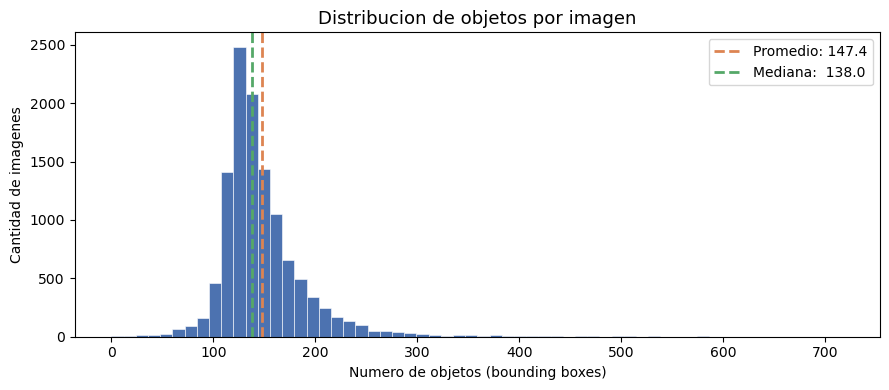

In [5]:
promedio  = df['num_boxes'].mean()
minimo    = df['num_boxes'].min()
maximo    = df['num_boxes'].max()
mediana   = df['num_boxes'].median()

print(f'Promedio de objetos por imagen : {promedio:.1f}')
print(f'Mediana                        : {mediana:.1f}')
print(f'Minimo                         : {minimo}')
print(f'Maximo                         : {maximo}')

# Histograma de la distribucion
fig, ax = plt.subplots(figsize=(9, 4))

ax.hist(df['num_boxes'], bins=60, color='#4C72B0', edgecolor='white', linewidth=0.4)
ax.axvline(promedio, color='#DD8452', linewidth=2, linestyle='--', label=f'Promedio: {promedio:.1f}')
ax.axvline(mediana,  color='#55A868', linewidth=2, linestyle='--', label=f'Mediana:  {mediana:.1f}')

ax.set_title('Distribucion de objetos por imagen', fontsize=13)
ax.set_xlabel('Numero de objetos (bounding boxes)')
ax.set_ylabel('Cantidad de imagenes')
ax.legend()
plt.tight_layout()
plt.show()